# RetailIQ: Predictive Analytics and Customer Intelligence System

Five syllabus-aligned techniques using the UCI Online Retail dataset:
1. Multiple Linear Regression — daily revenue prediction
2. Logistic Regression — customer churn prediction
3. Decision Tree Classifier — churn classification
4. Support Vector Machine (SVM) — churn classification
5. K-Means Clustering — customer segmentation

Update `EXCEL_FILE` in the first code cell, then run all cells from top to bottom.

## 1. Load libraries and dataset

In [3]:
# If needed, run in a notebook cell: %pip install pandas numpy matplotlib scikit-learn openpyxl
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, log_loss,
    silhouette_score
)

# Change this path to where you saved Online Retail.xlsx
EXCEL_FILE = r"C:\Users\vishnutejakarrolla\Desktop\Projects\RetailIQ_project\RetailIQ_Easy_Code\data\Online Retail.xlsx"
if not os.path.exists(EXCEL_FILE):
    raise FileNotFoundError("Update EXCEL_FILE with the correct path to Online Retail.xlsx")

df = pd.read_excel(EXCEL_FILE)
print("Original shape:", df.shape)
print(df.columns.tolist())
display(df.head())
display(df.info())

Original shape: (541909, 8)
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


None

## 2. Data preprocessing

In [4]:
# Convert date and remove rows with missing essential values.
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df = df.dropna(subset=["InvoiceNo", "StockCode", "Description", "Quantity",
                       "InvoiceDate", "UnitPrice", "CustomerID"])
df["CustomerID"] = df["CustomerID"].astype(str).str.replace(r"\.0$", "", regex=True)
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")
df = df.dropna(subset=["Quantity", "UnitPrice"])

# Remove cancelled invoices and invalid quantity/price values.
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
df = df.drop_duplicates().copy()
df["Revenue"] = df["Quantity"] * df["UnitPrice"]
df = df.sort_values("InvoiceDate").reset_index(drop=True)

print("Cleaned shape:", df.shape)
print("Unique customers:", df["CustomerID"].nunique())
print("Unique invoices:", df["InvoiceNo"].nunique())
print("Missing values:\n", df.isnull().sum())

Cleaned shape: (392692, 9)
Unique customers: 4338
Unique invoices: 18532
Missing values:
 InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
Revenue        0
dtype: int64


## 3. Exploratory data analysis

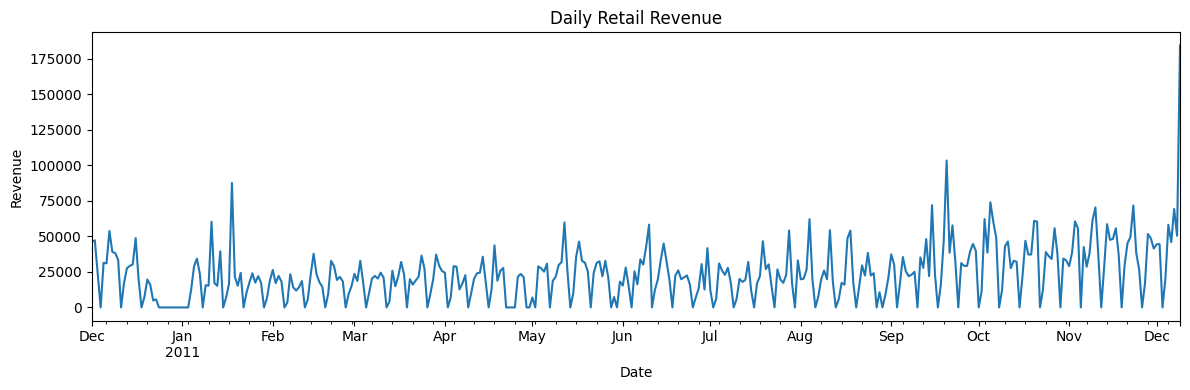

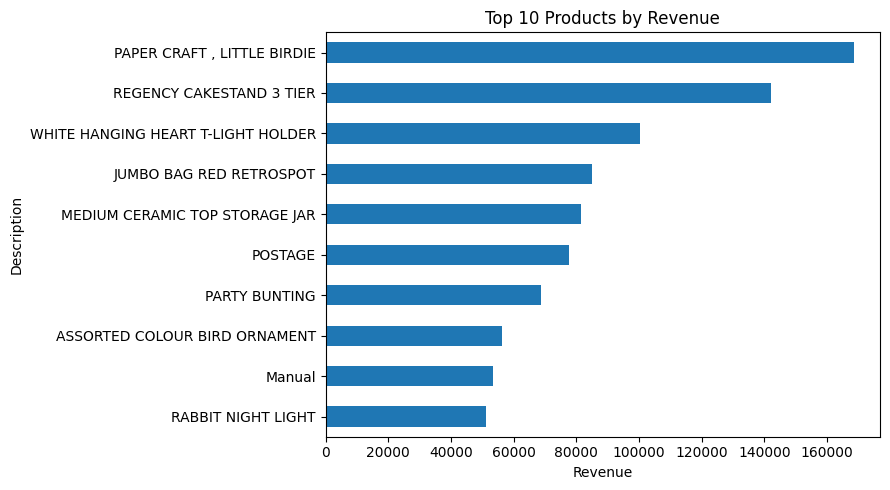

In [5]:
daily_sales = df.set_index("InvoiceDate")["Revenue"].resample("D").sum()
daily_sales.plot(figsize=(12, 4), title="Daily Retail Revenue")
plt.xlabel("Date"); 
plt.ylabel("Revenue");
plt.tight_layout(); 
plt.show()

top_products = df.groupby("Description")["Revenue"].sum().nlargest(10)
top_products.sort_values().plot(kind="barh", figsize=(9, 5), title="Top 10 Products by Revenue")
plt.xlabel("Revenue"); 
plt.tight_layout(); 
plt.show()

## 4. Multiple Linear Regression — daily revenue prediction

MAE: 14033.14
MSE: 526573163.71
RMSE: 22947.18
R-squared: 0.2265


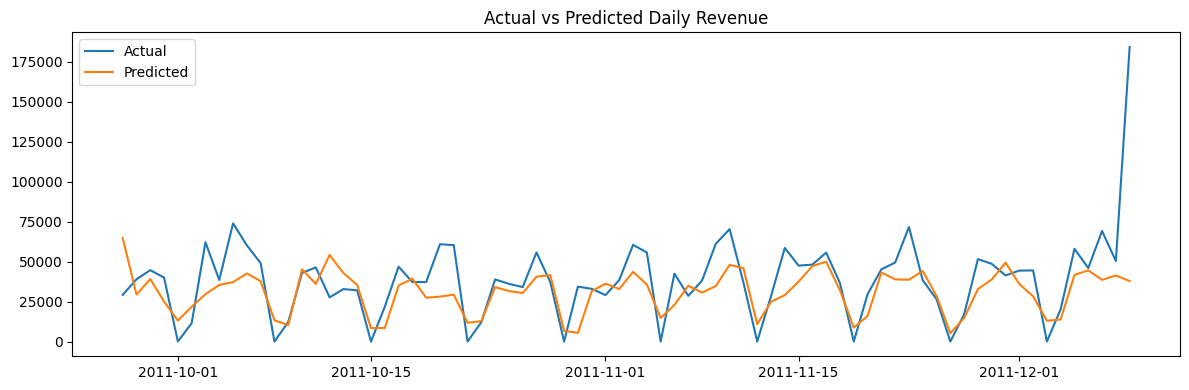

In [6]:
# Use past daily revenue and calendar values to predict daily revenue.
daily = df.set_index("InvoiceDate")["Revenue"].resample("D").sum().to_frame()
daily["Lag1"] = daily["Revenue"].shift(1)
daily["Lag2"] = daily["Revenue"].shift(2)
daily["Lag7"] = daily["Revenue"].shift(7)
daily["DayOfWeek"] = daily.index.dayofweek
daily["Month"] = daily.index.month
daily["DayOfMonth"] = daily.index.day
daily = daily.dropna()

features_reg = ["Lag1", "Lag2", "Lag7", "DayOfWeek", "Month", "DayOfMonth"]
X_reg, y_reg = daily[features_reg], daily["Revenue"]
cut = int(len(daily) * 0.8)
X_train_reg, X_test_reg = X_reg.iloc[:cut], X_reg.iloc[cut:]
y_train_reg, y_test_reg = y_reg.iloc[:cut], y_reg.iloc[cut:]

reg_model = LinearRegression()
reg_model.fit(X_train_reg, y_train_reg)
pred_reg = reg_model.predict(X_test_reg)

print("MAE:", round(mean_absolute_error(y_test_reg, pred_reg), 2))
print("MSE:", round(mean_squared_error(y_test_reg, pred_reg), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test_reg, pred_reg)), 2))
print("R-squared:", round(r2_score(y_test_reg, pred_reg), 4))

plt.figure(figsize=(12, 4))
plt.plot(y_test_reg.index, y_test_reg, label="Actual")
plt.plot(y_test_reg.index, pred_reg, label="Predicted")
plt.title("Actual vs Predicted Daily Revenue"); plt.legend(); plt.tight_layout(); plt.show()

## 5. Create customer churn features

Churn is defined here as no purchase in the 90 days after a snapshot date. Features use only transactions before each snapshot.

In [7]:
def make_customer_snapshot(data, snapshot_date, history_days=180, churn_days=90):
    snapshot = pd.Timestamp(snapshot_date)
    history = data[
        (data["InvoiceDate"] < snapshot) &
        (data["InvoiceDate"] >= snapshot - pd.Timedelta(days=history_days))
    ].copy()
    future = data[
        (data["InvoiceDate"] >= snapshot) &
        (data["InvoiceDate"] < snapshot + pd.Timedelta(days=churn_days))
    ].copy()
    features = history.groupby("CustomerID").agg(
        Recency=("InvoiceDate", lambda x: (snapshot - x.max()).days),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("Revenue", "sum"),
        Quantity=("Quantity", "sum"),
        AverageOrderValue=("Revenue", "mean")
    )
    active_in_future = set(future["CustomerID"].unique())
    features["Churn"] = (~features.index.isin(active_in_future)).astype(int)
    return features.reset_index()

# Dataset extends through December 2011, allowing a full 90-day label window.
train_customers = make_customer_snapshot(df, "2011-05-31")
test_customers = make_customer_snapshot(df, "2011-09-01")
feature_cols = ["Recency", "Frequency", "Monetary", "Quantity", "AverageOrderValue"]
X_train, y_train = train_customers[feature_cols], train_customers["Churn"]
X_test, y_test = test_customers[feature_cols], test_customers["Churn"]

print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("Training churn distribution:\n", y_train.value_counts())

Train rows: 2680 | Test rows: 2772
Training churn distribution:
 Churn
0    1342
1    1338
Name: count, dtype: int64


## 6. Classification evaluation helper

In [8]:
def evaluate_classifier(name, model):
    predictions = model.predict(X_test)
    print("\\n" + name)
    print("Accuracy :", round(accuracy_score(y_test, predictions), 4))
    print("Precision:", round(precision_score(y_test, predictions, zero_division=0), 4))
    print("Recall   :", round(recall_score(y_test, predictions, zero_division=0), 4))
    print("F1-score :", round(f1_score(y_test, predictions, zero_division=0), 4))
    print(classification_report(y_test, predictions, zero_division=0))
    matrix = confusion_matrix(y_test, predictions)
    plt.figure(figsize=(4, 3)); 
    plt.imshow(matrix)
    plt.title(name + " - Confusion Matrix")
    plt.xlabel("Predicted");
    plt.ylabel("Actual")
    plt.xticks([0, 1], ["Active", "Churn"]); 
    plt.yticks([0, 1], ["Active", "Churn"])
    for (i, j), value in np.ndenumerate(matrix):
        plt.text(j, i, str(value), ha="center", va="center")
    plt.tight_layout(); plt.show()
    if hasattr(model, "predict_proba") and len(np.unique(y_test)) == 2:
        probabilities = model.predict_proba(X_test)
        print("ROC-AUC:", round(roc_auc_score(y_test, probabilities[:, 1]), 4))
        print("Log loss:", round(log_loss(y_test, probabilities), 4))

## 7. Logistic Regression

\nLogistic Regression
Accuracy : 0.6432
Precision: 0.5311
Recall   : 0.7833
F1-score : 0.633
              precision    recall  f1-score   support

           0       0.80      0.55      0.65      1683
           1       0.53      0.78      0.63      1089

    accuracy                           0.64      2772
   macro avg       0.66      0.67      0.64      2772
weighted avg       0.69      0.64      0.65      2772



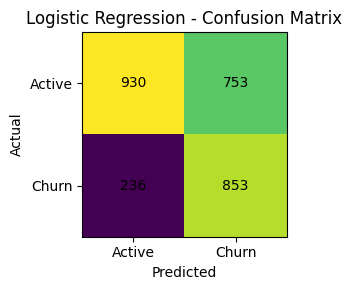

ROC-AUC: 0.7281
Log loss: 0.6088


In [7]:
logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))
])
logistic_model.fit(X_train, y_train)
evaluate_classifier("Logistic Regression", logistic_model)

## 8. Decision Tree Classifier

\nDecision Tree
Accuracy : 0.6407
Precision: 0.5279
Recall   : 0.809
F1-score : 0.6389
              precision    recall  f1-score   support

           0       0.81      0.53      0.64      1683
           1       0.53      0.81      0.64      1089

    accuracy                           0.64      2772
   macro avg       0.67      0.67      0.64      2772
weighted avg       0.70      0.64      0.64      2772



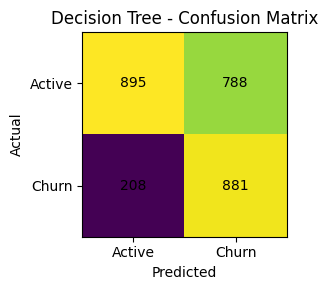

ROC-AUC: 0.7165
Log loss: 0.6182


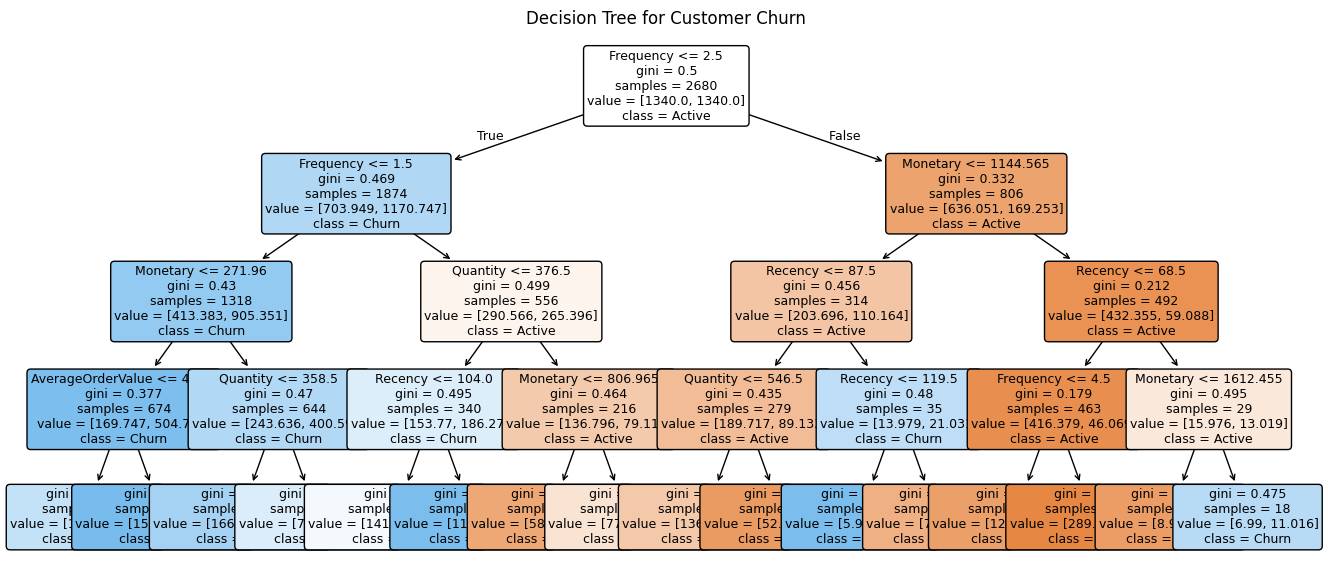

In [8]:
tree_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(max_depth=4, min_samples_leaf=10,
                                     class_weight="balanced", random_state=42))
])
tree_model.fit(X_train, y_train)
evaluate_classifier("Decision Tree", tree_model)

plt.figure(figsize=(16, 7))
plot_tree(tree_model.named_steps["model"], feature_names=feature_cols,
          class_names=["Active", "Churn"], filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree for Customer Churn"); 
plt.show()

## 9. Support Vector Machine (SVM)

\nSupport Vector Machine (SVM)
Accuracy : 0.6407
Precision: 0.5276
Recall   : 0.8154
F1-score : 0.6407
              precision    recall  f1-score   support

           0       0.82      0.53      0.64      1683
           1       0.53      0.82      0.64      1089

    accuracy                           0.64      2772
   macro avg       0.67      0.67      0.64      2772
weighted avg       0.70      0.64      0.64      2772



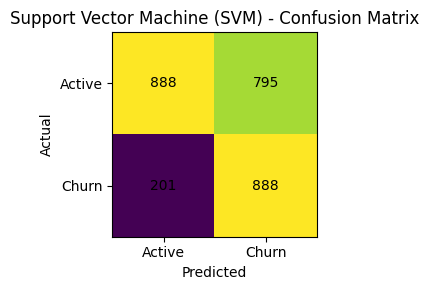

ROC-AUC: 0.7255
Log loss: 0.6111


In [9]:
svm_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", SVC(kernel="rbf", C=1.0, probability=True,
                  class_weight="balanced", random_state=42))
])
svm_model.fit(X_train, y_train)
evaluate_classifier("Support Vector Machine (SVM)", svm_model)

## 10. K-Means Clustering — customer segmentation

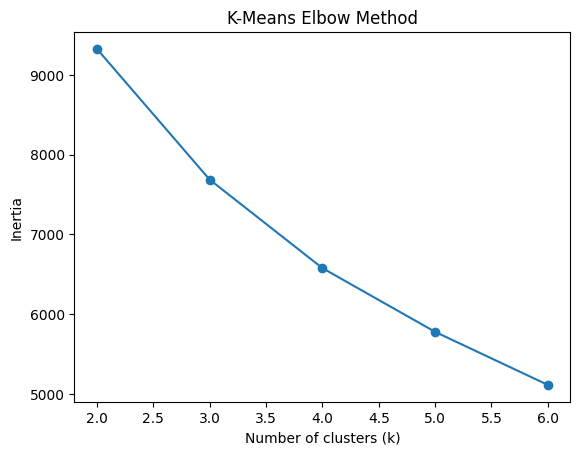

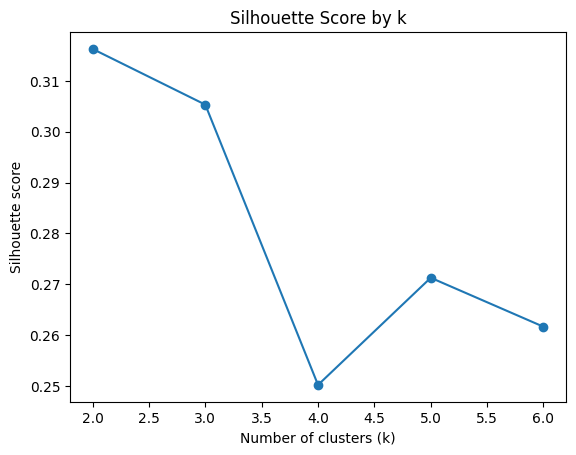

Selected k: 2
Cluster
0    1175
1    1597
Name: count, dtype: int64


,Recency,Frequency,Monetary,Quantity,AverageOrderValue
Cluster,,,,,
0,32.18,4.83,2592.37,1539.64,61.34
1,90.17,1.35,315.86,174.24,24.43


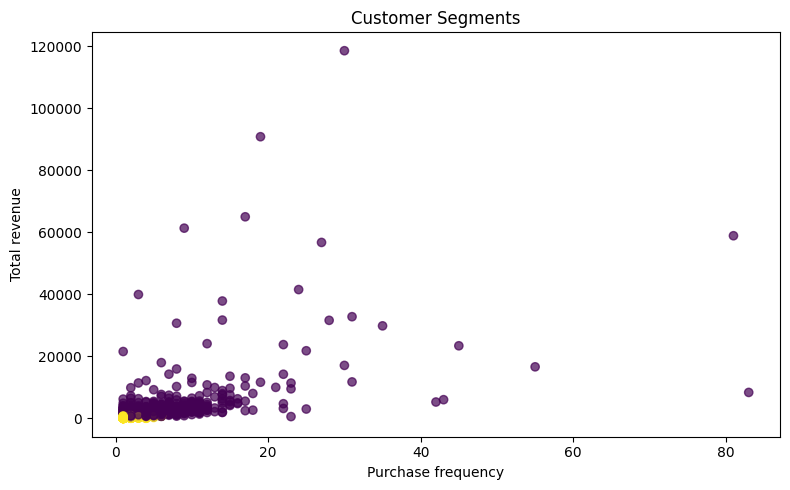

In [9]:
# K-Means is unsupervised: it does not use the Churn target.
segment_customers = make_customer_snapshot(df, "2011-09-01")
segment_data = segment_customers[feature_cols].copy()

# Log-transform skewed values and scale all features.
for col in ["Monetary", "Quantity", "AverageOrderValue"]:
    segment_data[col] = np.log1p(segment_data[col].clip(lower=0))
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
segment_scaled = scaler.fit_transform(imputer.fit_transform(segment_data))

k_values = list(range(2, 7))
inertias, silhouettes = [], []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(segment_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(
        segment_scaled, labels, sample_size=min(2000, len(segment_scaled)), random_state=42
    ))

plt.plot(k_values, inertias, marker="o")
plt.title("K-Means Elbow Method"); plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia"); plt.show()

plt.plot(k_values, silhouettes, marker="o")
plt.title("Silhouette Score by k"); plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score"); plt.show()

best_k = k_values[int(np.argmax(silhouettes))]
print("Selected k:", best_k)
kmeans_model = KMeans(n_clusters=best_k, n_init=10, random_state=42)
segment_customers["Cluster"] = kmeans_model.fit_predict(segment_scaled)

print(segment_customers["Cluster"].value_counts().sort_index())
display(segment_customers.groupby("Cluster")[feature_cols].mean().round(2))

plt.figure(figsize=(8, 5))
plt.scatter(segment_customers["Frequency"], segment_customers["Monetary"],
            c=segment_customers["Cluster"], alpha=0.7)
plt.xlabel("Purchase frequency"); plt.ylabel("Total revenue")
plt.title("Customer Segments"); plt.tight_layout(); plt.show()

## 11. Compare classification models

,Accuracy,Precision,Recall,F1-score
Model,,,,
Logistic Regression,0.6432,0.5311,0.7833,0.6330
Decision Tree,0.6407,0.5279,0.8090,0.6389
SVM,0.6407,0.5276,0.8154,0.6407


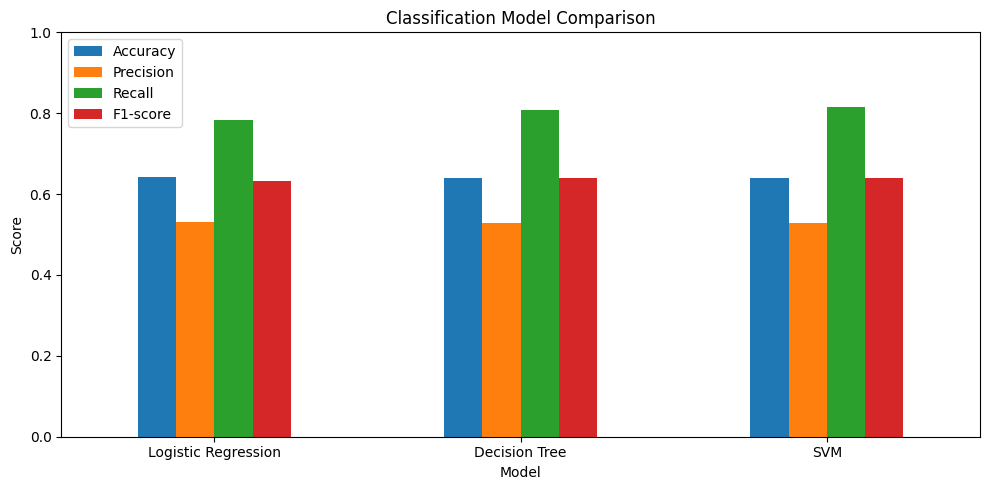

In [11]:
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": tree_model,
    "SVM": svm_model
}
rows = []
for name, model in models.items():
    predictions = model.predict(X_test)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0)
    })
comparison = pd.DataFrame(rows).set_index("Model")
display(comparison.round(4))
comparison.plot(kind="bar", ylim=(0, 1), figsize=(10, 5), title="Classification Model Comparison")
plt.ylabel("Score"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 12. Conclusion

This notebook applies regression, classification, and clustering to real retail transaction data. Regression is evaluated with MAE, MSE, RMSE, and R-squared. Classification is evaluated with accuracy, precision, recall, F1-score, confusion matrix, ROC-AUC, and log loss where applicable. K-Means groups customers based on purchasing behaviour.

**For your report/viva:** clearly state that churn means no purchase during the 90-day period after the snapshot date. Results depend on the dataset and this definition.